# K-means: Grouping Community Areas by How They Use Rideshare

Goal: group Chicago's 77 community areas by their rideshare usage profile (issue #12).

Data: the cleaned trips from 2023 onward (after the COVID break), summarized per pickup community area by `src/mining/kmeans_areas.py` on Dataproc. Each area gets 12 features: the share of its trips in five time bands, the weekend share, the share going downtown, to the airports or staying in the same area, average distance, average fare, and trips per km² (log scale). Features are standardized before clustering, and K-means is run for k = 2 to 10.

In [2]:
from pathlib import Path
import glob
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

# Folder with the Dataproc outputs (downloaded with gcloud storage cp -r).
# Use "mining_test" for the 200k-sample test run, "mining" for the full-data run.
RESULTS = ROOT / "results" / "mining"
FIGS = ROOT / "docs" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

def read_spark_csv(name):
    """Spark writes each output as a folder with one part-*.csv file inside."""
    files = glob.glob(str(RESULTS / name / "part-*.csv"))
    assert files, f"no CSV found in {RESULTS / name}"
    return pd.read_csv(files[0])

scores = read_spark_csv("kmeans_scores").sort_values("k")
clusters = read_spark_csv("kmeans_clusters")
profile = read_spark_csv("area_profile")
profile["name"] = profile["name"].replace({"Ohare": "O'Hare"})
print(len(profile), "areas,", len(scores), "values of k")
scores

77 areas, 9 values of k


,k,silhouette,cost
0,2,0.579327,628.203645
1,3,0.642933,480.537115
2,4,0.598663,421.255035
3,5,0.373662,451.617098
4,6,0.271403,382.672839
5,7,0.277655,330.652412
6,8,0.432953,283.377401
7,9,0.277325,258.443751
8,10,0.197957,261.715546


## Choosing k: elbow and silhouette

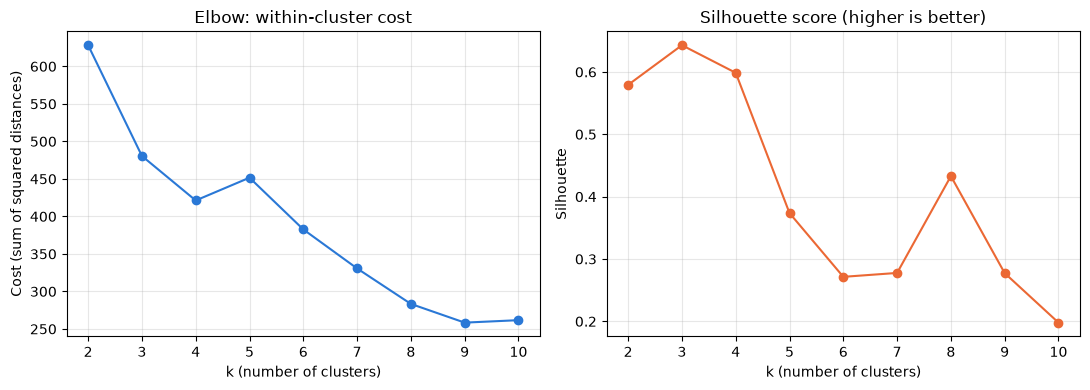

Chosen k: 3 | silhouette: 0.643


In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(scores["k"], scores["cost"], marker="o", color="#2a78d6")
a1.set(title="Elbow: within-cluster cost", xlabel="k (number of clusters)", ylabel="Cost (sum of squared distances)")
a2.plot(scores["k"], scores["silhouette"], marker="o", color="#eb6834")
a2.set(title="Silhouette score (higher is better)", xlabel="k (number of clusters)", ylabel="Silhouette")
for a in (a1, a2):
    a.set_xticks(scores["k"]); a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGS / "kmeans_choose_k.png", dpi=150, bbox_inches="tight")
plt.show()

# k = 2 usually just splits downtown from everything else, so pick the best silhouette from k = 3 to 8.
# If the elbow chart suggests a different k, set K by hand here and say why in the text below.
K = int(scores[scores["k"].between(3, 8)].sort_values("silhouette", ascending=False)["k"].iloc[0])
print("Chosen k:", K, "| silhouette:", round(scores.set_index("k").loc[K, "silhouette"], 3))

We picked k = 3. It has the highest silhouette score (0.643), which means the areas are well separated into three groups. k = 2 scores a bit lower (0.579), and after k = 4 the silhouette drops a lot (0.374 at k = 5 and 0.27 at k = 6). k = 8 has a smaller second peak (0.433), but with 77 areas that would give very small groups that are hard to explain. The elbow chart mostly agrees: the cost drops the most from k = 2 to k = 3. The cost goes up from k = 4 to k = 5, which should not happen in theory. This is because K-means starts from random centers and can end in a worse grouping, so the scores are not perfectly smooth.

## What each cluster looks like

In [4]:
FEATURES = ["share_night", "share_morning", "share_midday", "share_evening", "share_late",
            "share_weekend", "share_to_downtown", "share_to_airport", "share_same_area",
            "avg_miles", "avg_fare", "log_trips_per_km2"]
assign = clusters[clusters["k"] == K][["area", "cluster"]]
df = profile.merge(assign, on="area")

summary = df.groupby("cluster").agg(
    areas=("area", "count"),
    trips=("trips", "sum"),
    **{f: (f, "mean") for f in FEATURES},
    dist_to_L_km=("dist_to_L_km", "mean"))
summary["example_areas"] = df.sort_values("trips", ascending=False).groupby("cluster")["name"] \
    .apply(lambda s: ", ".join(s.head(4)))
summary.round(3)

,areas,trips,share_night,share_morning,share_midday,share_evening,share_late,share_weekend,share_to_downtown,share_to_airport,share_same_area,avg_miles,avg_fare,log_trips_per_km2,dist_to_L_km,example_areas
cluster,,,,,,,,,,,,,,,,
0,17,189897264,0.125,0.132,0.265,0.252,0.226,0.357,0.319,0.065,0.126,5.364,15.030,6.034,0.756,"Near North Side, Near West Side, Loop, Lake View"
1,58,87134312,0.110,0.203,0.325,0.211,0.150,0.278,0.135,0.044,0.118,6.683,13.927,5.247,2.501,"Austin, Rogers Park, South Shore, West Ridge"
2,2,20804624,0.090,0.130,0.323,0.239,0.219,0.248,0.470,0.065,0.054,15.681,32.530,5.654,1.670,"O'Hare, Garfield Ridge"


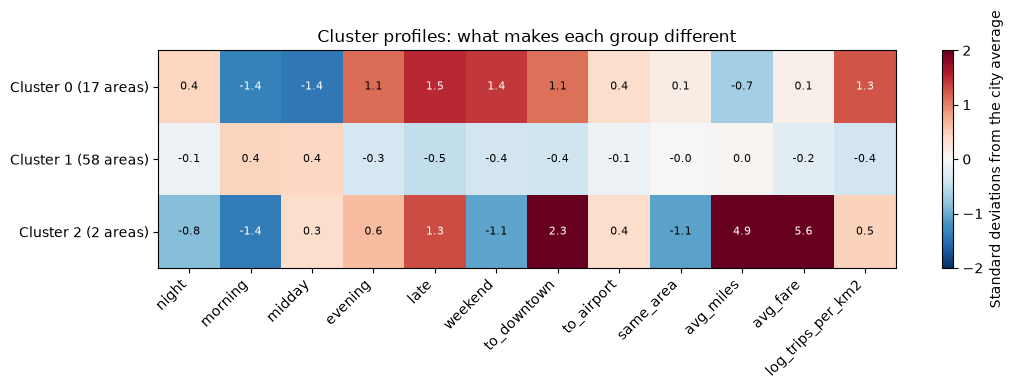

In [5]:
# How far each cluster is from the city average on each feature (in standard deviations)
z = (df[FEATURES] - df[FEATURES].mean()) / df[FEATURES].std()
z["cluster"] = df["cluster"]
centers = z.groupby("cluster")[FEATURES].mean()

fig, ax = plt.subplots(figsize=(11, 0.6 * K + 2))
im = ax.imshow(centers, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(FEATURES)), [f.replace("share_", "") for f in FEATURES], rotation=45, ha="right")
ax.set_yticks(range(K), [f"Cluster {c} ({(df.cluster == c).sum()} areas)" for c in centers.index])
for i in range(K):
    for j in range(len(FEATURES)):
        v = centers.iloc[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 1.2 else "black")
fig.colorbar(im, ax=ax, label="Standard deviations from the city average")
ax.set_title("Cluster profiles: what makes each group different")
plt.tight_layout()
plt.savefig(FIGS / "kmeans_cluster_profiles.png", dpi=150, bbox_inches="tight")
plt.show()

Cluster 0 – Central and lakefront, evenings and weekends (17 areas). These areas have 189.9 million trips, about 64% of all trips we clustered. They have the most evening (25%), late-night (23%) and weekend (36%) trips, and the fewest morning trips (13%). About 32% of their trips go downtown. They also have the highest trip density per km². This looks like nightlife and leisure travel in dense neighborhoods.

Cluster 1 – Rest of the city, daytime trips (58 areas). Most areas fall in this group, but it has only 87.1 million trips (about 29%). It has more morning (20%) and midday (33%) trips than the other clusters, fewer weekend trips (28%), and only 14% of trips go downtown. Trip density is lower. This looks like everyday local travel, like going to work, school or errands.

Cluster 2 – Airports (2 areas). O'Hare and Garfield Ridge (where Midway airport is), with 20.8 million trips (about 7%). Their trips are much longer and more expensive than everywhere else: average distance is 4.9 and average fare 5.6 standard deviations above the city average. 47% of their trips go downtown, and they have fewer weekend and morning trips.

## Map of the clusters

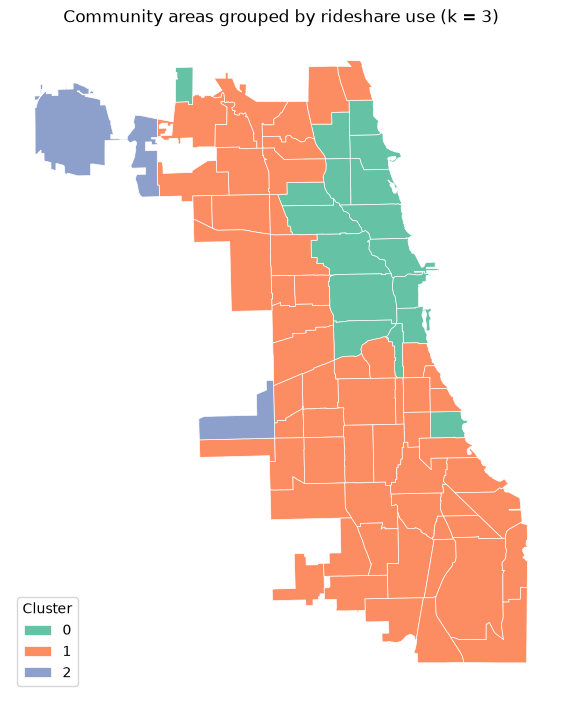

In [6]:
areas = gpd.read_file(ROOT / "data" / "raw" / "supporting" / "community_areas.geojson")
num_col = [c for c in areas.columns if c.lower().startswith("area_num")][0]
areas["area"] = areas[num_col].astype(float).astype(int)
m = areas.merge(df[["area", "name", "cluster", "dist_to_L_km"]], on="area")
m["cluster"] = m["cluster"].astype(str)

ax = m.plot(column="cluster", categorical=True, cmap="Set2", legend=True, figsize=(7, 9),
            edgecolor="white", linewidth=0.5,
            legend_kwds={"title": "Cluster", "loc": "lower left"})
ax.set_axis_off()
ax.set_title(f"Community areas grouped by rideshare use (k = {K})")
plt.savefig(FIGS / "kmeans_clusters_map.png", dpi=150, bbox_inches="tight")
plt.show()

Cluster 0 is one connected block: the Loop, Near North Side, Near West Side and the North Side neighborhoods along the lake, plus Hyde Park on the South Side. Most of this block is along the Red, Brown, Purple and Blue 'L' lines, so these areas have good train access and still use rideshare a lot, mainly in the evening and on weekends. Cluster 1 covers almost all of the South Side, the West Side and the far Northwest Side. Comparing with Yousuf's map (docs/figures/cta_distance_map.png), many of these areas are farther from an 'L' station. Cluster 2 is just the two airports. One small area in the far northwest(Edison Park, only about 324,000 trips) is in Cluster 0 even though it is far from downtown; it has few trips, so its profile may not be reliable.

## Save the cluster for each area

In [7]:
out = df[["area", "name", "cluster", "trips", "dist_to_L_km"]].sort_values(["cluster", "area"])
out.to_csv(ROOT / "results" / "kmeans_area_clusters.csv", index=False)
print("saved", len(out), "areas to results/kmeans_area_clusters.csv")
out.groupby("cluster")["name"].apply(lambda s: ", ".join(s)).to_frame("areas")

saved 77 areas to results/kmeans_area_clusters.csv


,areas
cluster,
0,"Uptown, Lincoln Square, North Center, Lake Vie..."
1,"Rogers Park, West Ridge, Norwood Park, Jeffers..."
2,"Garfield Ridge, O'Hare"


## What this means for the project

- Rideshare use is not the same as a transit gap. Cluster 0 has the most trips, but it also has the best 'L' access, so its trips are mostly about convenience at night and on weekends.
- Cluster 1 is where we should look for transit gaps: daytime, everyday trips in areas that are often far from the 'L'. In Sprint 3 we will combine trips per person, distance to the 'L' and income for these areas into the transit-gap score.
- We will use the cluster of each area (saved in results/kmeans_area_clusters.csv) as a feature in the demand model, and we will look at airport trips (Cluster 2) separately because they behave very differently.